# 03 · Training analysis

This notebook checks that every model **trained correctly** before its results are interpreted:

| Model | Folder in `experiments/` | Logged per epoch |
|---|---|---|
| PE MFGraph GNN | `pe_gnn_training/<run>/metrics.csv` | train/test loss, AUC, F1, accuracy, precision, recall |
| NIDS MFGraph GNN | `nids_gnn_training/<run>/nids_training_metrics.csv` | train loss, val F1, val AUC |
| PE / NIDS GAN-augmented classifier | `*_gan_training/<run>/metrics.csv` | as PE GNN |
| Dropout-WGAN-GP | `*_gan_training/<run>/gan_metrics.csv` | critic loss, generator loss, Wasserstein distance, gradient penalty, feature-mean gap |

The latest run that contains each file is used. The last section compares all runs to show how stable training is.

In [1]:
import sys
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

project_root = Path.cwd().resolve().parent
if str(project_root) not in sys.path:
    sys.path.append(str(project_root))

from src.utils.config import CONFIG

EXP = project_root / CONFIG["experiments_path"]
sns.set_theme(style="whitegrid")
plt.rcParams.update({"font.size": 11, "figure.dpi": 110})
GNN_NAME = "GNN (MFGraph)"


def latest_run(base: Path, filename: str):
    """Most recent timestamped run folder under `base` that contains `filename`."""
    runs = sorted(p.parent for p in base.glob(f"*/{filename}")) if base.exists() else []
    return runs[-1] if runs else None


def missing(path, task):
    print(f"[Missing] {path}\nRun first:  python orchestrator.py -t {task}")

def load_latest(sub, filename, task):
    run = latest_run(EXP / sub, filename)
    if run is None:
        missing(EXP / sub / "<run>" / filename, task)
        return None, None
    print(f"[{sub}] using run {run.name}")
    return pd.read_csv(run / filename), run


def plot_classifier(df, title, loss_cols, metric_cols, epoch_col="epoch"):
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 4.5))
    for c in loss_cols:
        a1.plot(df[epoch_col], df[c], marker="o", ms=3, label=c)
    a1.set_title(f"{title} — loss"); a1.set_xlabel("Epoch"); a1.legend()
    for c in metric_cols:
        a2.plot(df[epoch_col], df[c], marker="o", ms=3, label=c)
    a2.set_title(f"{title} — evaluation metrics"); a2.set_xlabel("Epoch"); a2.set_ylim(0, 1.02); a2.legend()
    plt.tight_layout(); plt.show()

## 1. PE MFGraph GNN (train = Jan 2018, evaluated on held-out graphs)

[pe_gnn_training] using run 20261020_175122


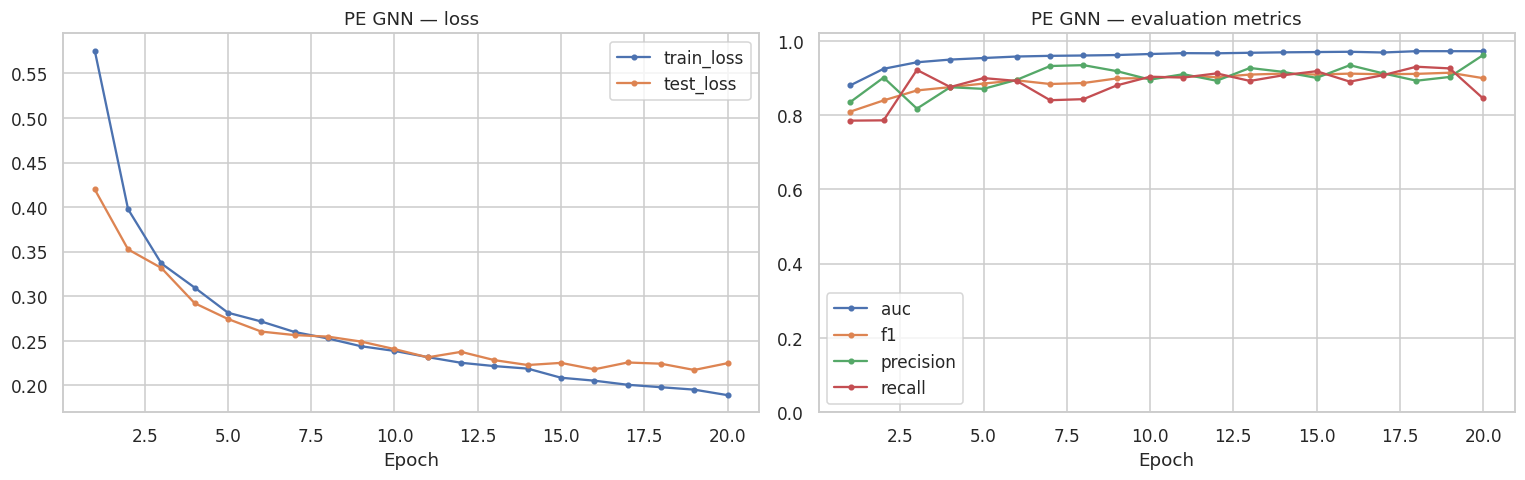

,train_loss,test_loss,auc,f1,accuracy,precision,recall
"epoch (best AUC, last)",,,,,,,
18,0.1980,0.2244,0.9723,0.9113,0.9063,0.8928,0.9305
20,0.1891,0.2250,0.9722,0.8997,0.9026,0.9618,0.8452


In [2]:
pe_gnn, _ = load_latest("pe_gnn_training", "metrics.csv", "train_pe_gnn")
if pe_gnn is not None:
    plot_classifier(pe_gnn, "PE GNN", ["train_loss", "test_loss"], ["auc", "f1", "precision", "recall"])
    display(pe_gnn.iloc[[pe_gnn.auc.idxmax(), -1]].round(4).set_index("epoch").rename_axis("epoch (best AUC, last)"))

**How to read it.** The gap between train and test loss shows over-fitting; a test loss that rises while train loss keeps
falling means the last epochs are memorising. Precision and recall moving in opposite directions at fixed AUC means the
*ranking* is stable and only the 0.5 threshold moves, which is why the unified pipeline (06) recalibrates the threshold.

## 2. NIDS MFGraph GNN (chronological 80/10/10 split per scenario)

[nids_gnn_training] using run 20261021_105506


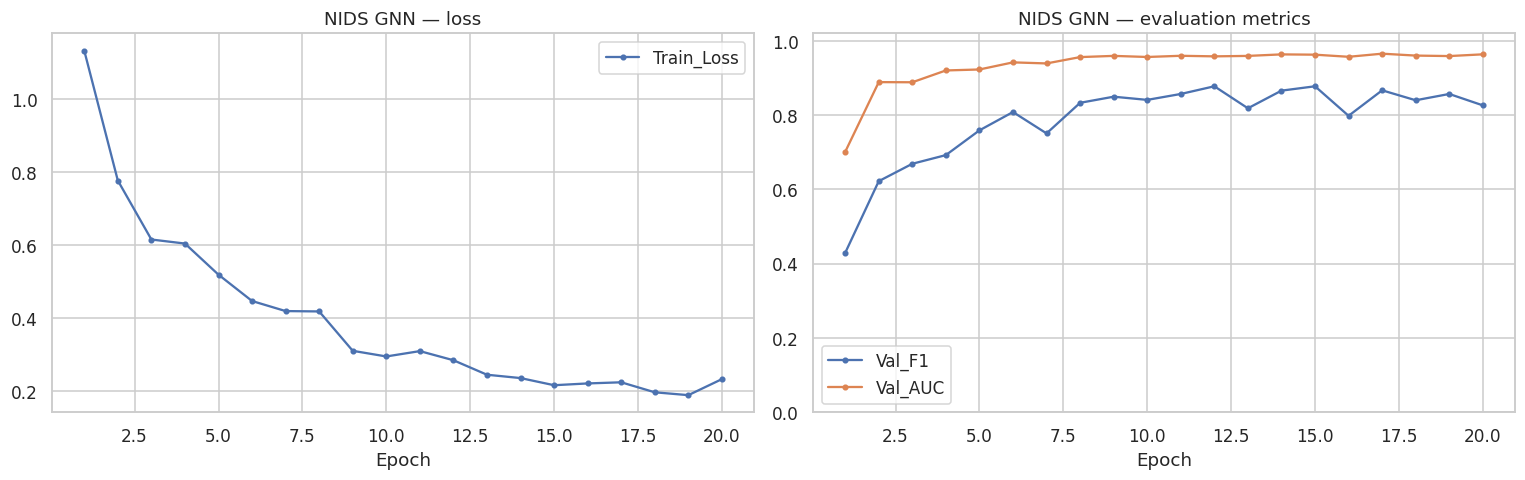

,Train_Loss,Val_F1,Val_AUC
Epoch,,,
17,0.2250,0.8670,0.9656
20,0.2336,0.8264,0.9638


In [3]:
nids_gnn, _ = load_latest("nids_gnn_training", "nids_training_metrics.csv", "train_nids_gnn")
if nids_gnn is not None:
    plot_classifier(nids_gnn, "NIDS GNN", ["Train_Loss"], ["Val_F1", "Val_AUC"], epoch_col="Epoch")
    display(nids_gnn.iloc[[nids_gnn.Val_AUC.idxmax(), -1]].round(4).set_index("Epoch"))

Validation F1 fluctuates more than AUC because the validation set has few malicious windows: a handful of flipped
windows changes F1 noticeably. AUC is the more stable model-selection signal here.

## 3. Dropout-WGAN-GP training

[pe_gan_training] using run 20261020_192313


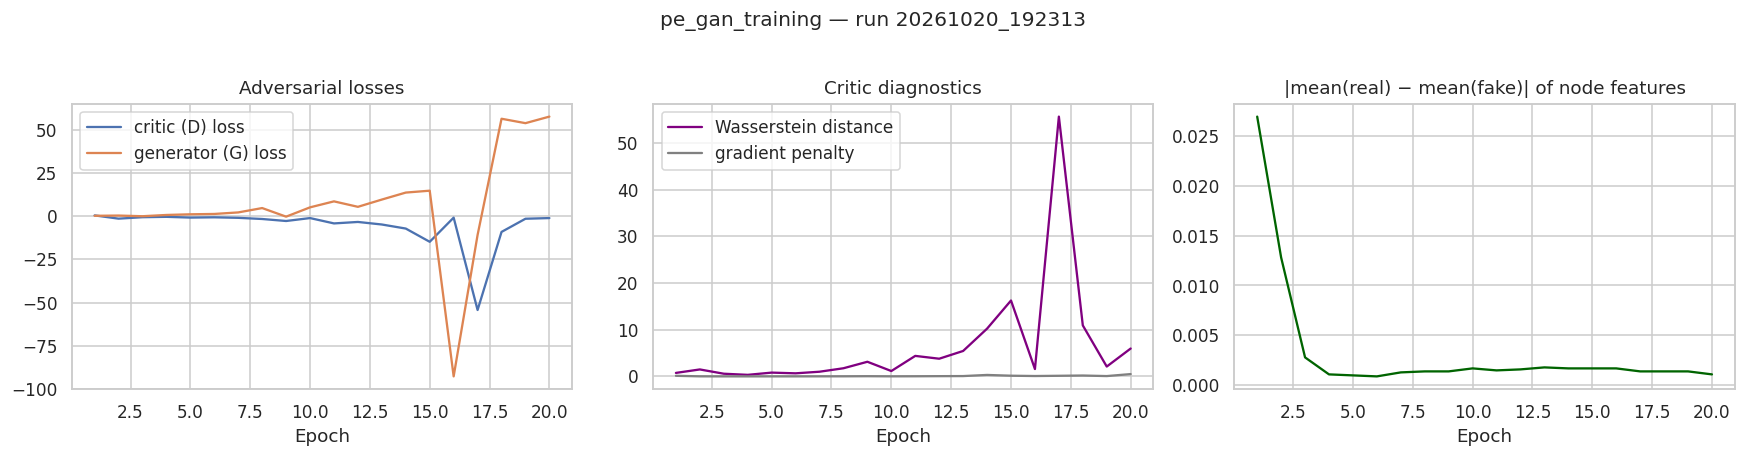

In [4]:
def plot_gan(sub, task):
    gan, run = load_latest(sub, "gan_metrics.csv", task)
    if gan is None:
        return
    fig, axes = plt.subplots(1, 3, figsize=(16, 4))
    axes[0].plot(gan.epoch, gan.d_loss, label="critic (D) loss"); axes[0].plot(gan.epoch, gan.g_loss, label="generator (G) loss")
    axes[0].set_title("Adversarial losses"); axes[0].legend()
    axes[1].plot(gan.epoch, gan.w_dist, color="purple", label="Wasserstein distance")
    axes[1].plot(gan.epoch, gan.gp, color="gray", label="gradient penalty"); axes[1].set_title("Critic diagnostics"); axes[1].legend()
    axes[2].plot(gan.epoch, gan.feat_mean_gap, color="darkgreen")
    axes[2].set_title("|mean(real) − mean(fake)| of node features")
    for a in axes:
        a.set_xlabel("Epoch")
    plt.suptitle(f"{sub} — run {run.name}", y=1.03); plt.tight_layout(); plt.show()

plot_gan("pe_gan_training", "train_pe_gan")

[nids_gan_training] using run 20261021_110256


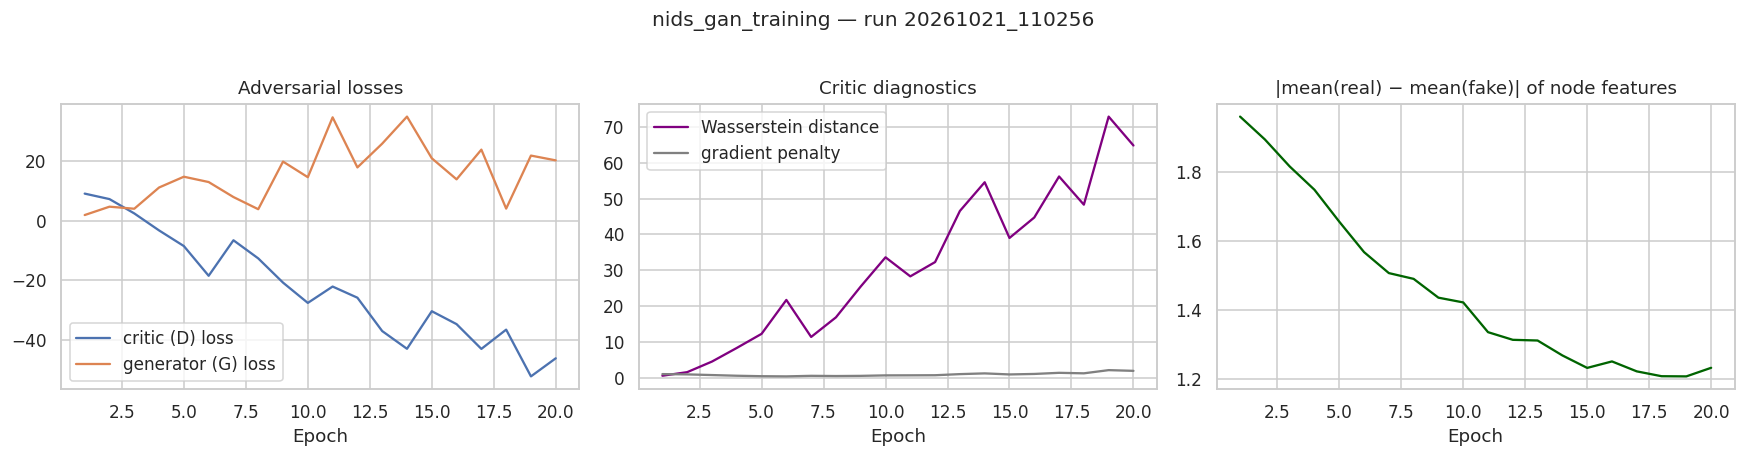

In [5]:
plot_gan("nids_gan_training", "train_nids_gan")

**How to read it.**
* In WGAN-GP the critic loss is ≈ −(Wasserstein distance). A distance that **grows steadily** means the critic separates real
  from fake more and more easily, i.e. the generator is **not catching up**; a stable or shrinking distance is the healthy case.
* The **feature-mean gap** is the most direct quality check: close to 0 means synthetic graphs match the first-order statistics of real malware.
* A gradient penalty that grows means the critic is leaving the 1-Lipschitz regime, often a sign that `lr_discriminator` or `n_critic` is too high.

For the PE GAN the mean gap is near zero although the Wasserstein distance spikes, so synthetic samples match the mean
but not the full distribution. For the NIDS GAN both the distance and the gap stay high: synthetic windows are clearly distinguishable
from real ones, which limits how much they can help as augmentation (compare section 4).

## 4. GAN-augmented classifiers

[pe_gan_training] using run 20261020_192313


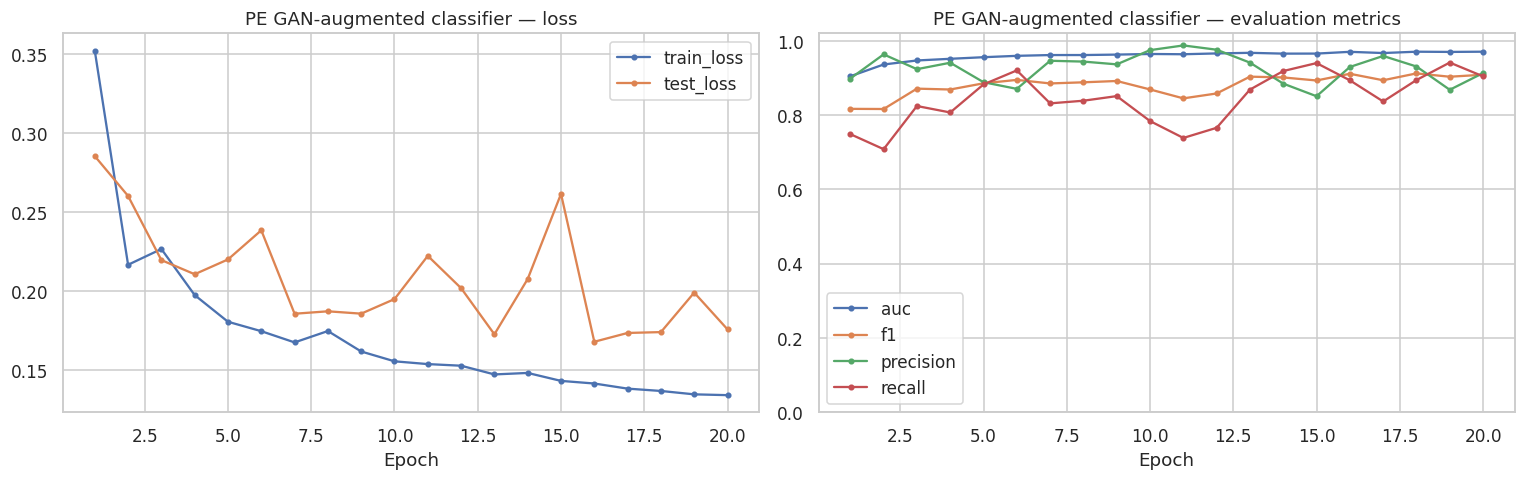

[nids_gan_training] using run 20261021_110256


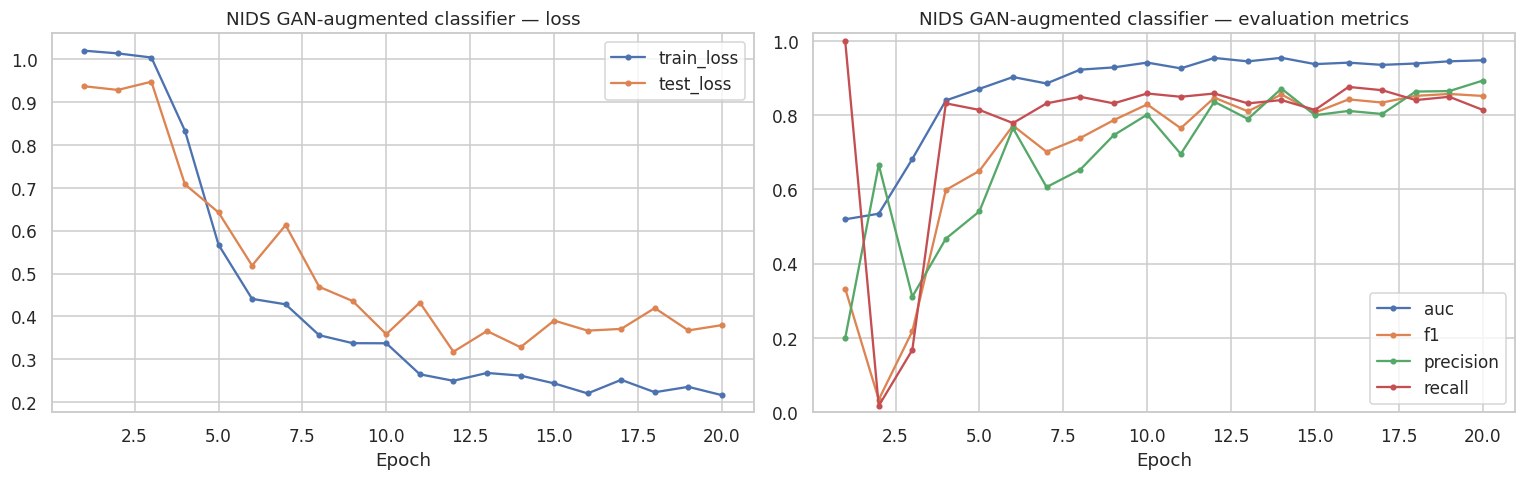

In [6]:
for sub, task in [("pe_gan_training", "train_pe_gan"), ("nids_gan_training", "train_nids_gan")]:
    df, _ = load_latest(sub, "metrics.csv", task)
    if df is not None:
        plot_classifier(df, f"{sub.split('_')[0].upper()} GAN-augmented classifier",
                        ["train_loss", "test_loss"], ["auc", "f1", "precision", "recall"])

In the first NIDS epochs the classifier can output the same class for everything (e.g. recall = 1.0 with precision = base
rate): that is the expected warm-up while the critic is still weak, and it is not a bug as long as the metrics recover afterwards.

## 5. Stability across runs

Final-epoch metrics of every run. A large spread between runs with the same config means the results in 04–06 should be
read with a margin of a few points.

In [7]:
rows = []
for sub, fname, metric in [("pe_gnn_training", "metrics.csv", "auc"), ("pe_gan_training", "metrics.csv", "auc"),
                           ("nids_gnn_training", "nids_training_metrics.csv", "Val_AUC"),
                           ("nids_gan_training", "metrics.csv", "auc")]:
    for f in sorted((EXP / sub).glob(f"*/{fname}")):
        df = pd.read_csv(f)
        rows.append({"model": sub.replace("_training", ""), "run": f.parent.name, "epochs": len(df),
                     "best AUC": df[metric].max(), "last AUC": df[metric].iloc[-1]})
runs = pd.DataFrame(rows)
display(runs.round(4))

,model,run,epochs,best AUC,last AUC
0,pe_gnn,20261019_121749,20,0.9777,0.9736
1,pe_gnn,20261020_175122,20,0.9723,0.9722
2,pe_gan,20261019_174242,20,0.9698,0.9686
3,pe_gan,20261020_123258,2,0.9433,0.9433
4,pe_gan,20261020_154926,14,0.9628,0.9628
5,pe_gan,20261020_192313,20,0.9709,0.9709
6,nids_gnn,20261020_112923,20,0.8994,0.8960
7,nids_gnn,20261021_105506,20,0.9656,0.9638
8,nids_gan,20261021_110256,20,0.9545,0.9478


**Takeaways for the thesis**
* Report the run used in 04–06 (the latest) and mention the spread between runs.
* Train and test loss stay close, so there is no strong over-fitting; however, the last PE epoch trades recall (0.93 → 0.85) for precision at almost
  identical AUC. The saved checkpoints are the **best-validation-F1** epoch (PE GNN) and **best-validation-AUC** epoch (NIDS GNN, GAN classifiers),
  not the last one — quote those epochs, not the final row, in the thesis.
* The two NIDS GNN runs differ a lot (best AUC 0.90 vs 0.97): state which config change caused this, otherwise it reads as instability.